# CASMI 2026 training data checks

`data/raw/casmi2026/train.parquet`: 2,539,608 spectra from 11 source libraries
([data finding](../../docs/findings/casmi2026_dataset_2026_10_05.md)).

Sections A-B repeat the checks of `nist20.ipynb`, `nist23.ipynb` and `nist23_data_quality.ipynb`
(composition, collision energy, peaks above the precursor, low-intensity peaks, peak-position
heuristics). Section C checks precursor m/z and formula labels. Section D replaces the DAG
coverage of `nist23_data_quality.ipynb` with **subformula coverage**: no DAGs are built.

Per-spectrum statistics come from a tracked script; rerun it before this notebook if the data
change:

```bash
PYTHONPATH=src python scripts/debug/casmi_enveda/casmi26_train_stats.py \
    --out_dp output/casmi26_train_check_2026_10_05 --workers 6
```

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap


def find_repo_root() -> Path:
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "src/fragnnet").is_dir():
            return candidate
    raise FileNotFoundError("Run this notebook from within the frag-gnn repository")


REPO_ROOT = find_repo_root()
TRAIN_FP = REPO_ROOT / "data/raw/casmi2026/train.parquet"
STATS_DP = REPO_ROOT / "output/casmi26_train_check_2026_10_05"

# Fixed categorical order (never cycled) and one sequential hue.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INST_ORDER = ["TOF", "ORB", "LR", "UNK"]
INST_COLORS = dict(zip(INST_ORDER, SERIES))
TRUE_COLOR, NULL_COLOR = SERIES[0], SERIES[1]
SEQ = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#86b6ef", "#2a78d6", "#1c5cab", "#0d366b"]
)
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e1e0d9",
        "grid.linewidth": 0.6,
        "axes.axisbelow": True,
        "figure.dpi": 110,
    }
)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

In [2]:
META_COLS = [
    "ingest_lib", "normalized_smiles", "inchikey14", "molecular_formula", "ionization_mode",
    "instrument_type", "adduct", "precursor_mz", "precursor_error_ppm", "num_peaks",
    "collision_energy_ev", "collision_energy_orig", "collision_energy_orig_units",
]
meta = pd.read_parquet(TRAIN_FP, columns=META_COLS)
stats = pd.read_parquet(STATS_DP / "casmi26_train_spec_stats.parquet")
mols = pd.read_parquet(STATS_DP / "casmi26_train_mol_stats.parquet")
run_info = json.loads((STATS_DP / "run_info.json").read_text())
if not np.array_equal(stats["row"].to_numpy(), np.arange(len(meta))):
    raise ValueError("Statistics are not aligned with train.parquet; rerun the stats script")

n_peak_mismatch = int((stats["num_peaks"].to_numpy() != meta["num_peaks"].to_numpy()).sum())
print(f"release num_peaks != length of ms2_mzs: {n_peak_mismatch:,} spectra")
df = pd.concat([meta, stats.drop(columns=["row", "num_peaks"])], axis=1)
# Flags are null where the subformula check was skipped; parquet returns them as object dtype,
# on which ~ is Python's integer invert. Use pandas' nullable boolean instead.
for col in ["has_prec_peak", "charged_formula", "sf_base_explained", "sf_base_explained_tight"]:
    df[col] = df[col].astype("boolean")
df["n_ce"] = df["collision_energy_ev"].map(lambda x: 0 if x is None else len(x))
df["ce_first"] = df["collision_energy_ev"].map(lambda x: x[0] if x is not None and len(x) else np.nan)
df = df.drop(columns="collision_energy_ev")
df["is_dimer"] = df["adduct"].str.match(r"^\[\dM")
df["is_multicharge"] = df["adduct"].str.contains(r"\][2-9][+-]$")
df["monomer_1z"] = ~df["is_dimer"] & ~df["is_multicharge"]
df["heavy_atoms"] = df["normalized_smiles"].map(mols.set_index("normalized_smiles")["heavy_atoms"])
LIB_ORDER = df["ingest_lib"].value_counts().index.tolist()

print(f"{len(df):,} spectra, {df.inchikey14.nunique():,} molecules (InChIKey first block)")
print(
    f"subformula check re-verified on {run_info['verify_checked']:,} spectra against "
    f"filter_subformula_peaks: {run_info['verify_mismatched']} mismatches"
)
print("stats run:", run_info["git"], f"{run_info['elapsed_s'] / 60:.0f} min")

release num_peaks != length of ms2_mzs: 0 spectra


2,539,608 spectra, 275,810 molecules (InChIKey first block)
subformula check re-verified on 4,192 spectra against filter_subformula_peaks: 0 mismatches
stats run: {'revision': '6f2fdea2b4ec3c7d3084f6243478fe1aadbb51fc', 'dirty': True} 13 min


## A. Composition

As in `nist20.ipynb` / `nist23.ipynb`. Instrument labels are free text; the stats script maps
them to four classes, which also set the matching tolerance in Section D:
TOF (QTOF, timsTOF, ...), ORB (Orbitrap and other FT), LR (ion trap, QQQ, sector) and UNK.

In [3]:
lib = df.groupby("ingest_lib").agg(
    spectra=("adduct", "size"),
    molecules=("inchikey14", "nunique"),
    positive=("ionization_mode", lambda s: (s == "positive").mean()),
    dimer=("is_dimer", "mean"),
    median_peaks=("num_peaks", "median"),
).loc[LIB_ORDER]
inst_share = pd.crosstab(df.ingest_lib, df.inst_class, normalize="index").reindex(columns=INST_ORDER, fill_value=0)
display(lib.join(inst_share).round(3))

In [4]:
# Instrument label -> class, largest labels per class
inst_map = (
    df.assign(instrument_label=df.instrument_type.fillna("<missing>"))
    .groupby(["inst_class", "instrument_label"]).size().rename("spectra").reset_index()
    .sort_values(["inst_class", "spectra"], ascending=[True, False])
)
print(df.inst_class.value_counts().reindex(INST_ORDER).to_string())
display(inst_map.groupby("inst_class").head(6).set_index(["inst_class", "instrument_label"]))

inst_class
TOF    1493117
ORB     950640
LR       61110
UNK      34741


spectra
inst_class instrument_label              
LR         LC-ESI-QQ                19283
           Linear Ion Trap          10241
           Flow-injection QqQ/MS     8721
           iontrap                   8595
           LC-ESI-QQQ                3097
           Ion Trap                  1958
ORB        Orbitrap                745562
           ESI-QFT                  77342
           LC-ESI-QFT               55024
           LC-ESI-ITFT              45109
           orbitrap                 15361
           Hybrid FT                 9137
TOF        timsTOF                1154969
           QTOF                    125936
           LC-ESI-QTOF             104482
           qTof                     33777
           ToF                      26535
           qtof                     26111
UNK        <missing>                33053
           nan                        972
           N/A                        376
                                      297
           in source CID               42
           LC-ESI-HRMS                  1

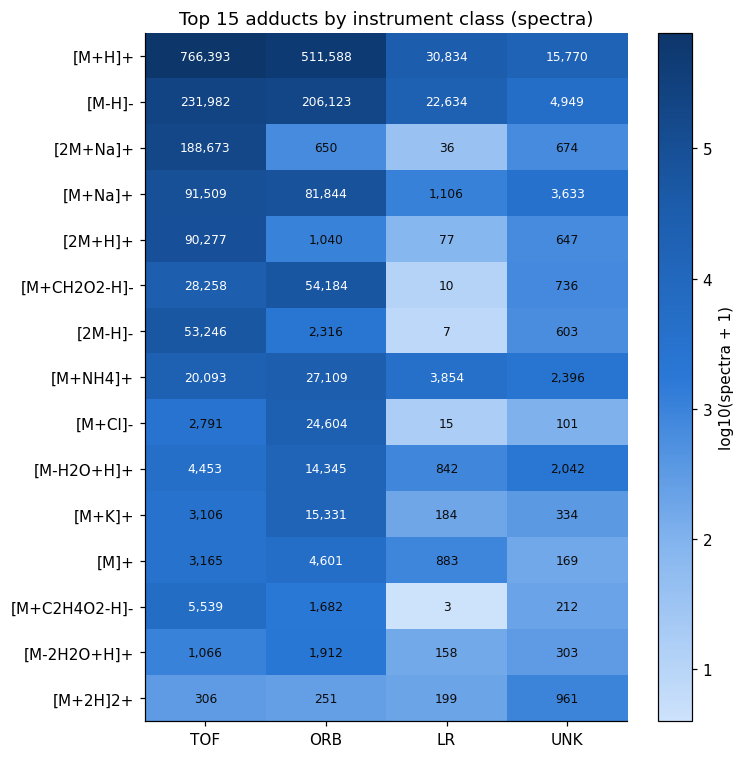

121 adduct strings in total


In [5]:
# Adduct x instrument class (nist20/23 heatmap), top 15 adducts
pivot = pd.crosstab(df.adduct, df.inst_class).reindex(columns=INST_ORDER, fill_value=0)
top15 = pivot.sum(axis=1).sort_values(ascending=False).head(15).index
heat = pivot.loc[top15]
log_heat = np.log10(heat.values + 1)

fig, ax = plt.subplots(figsize=(7, 7))
im = ax.imshow(log_heat, cmap=SEQ, aspect="auto")
ax.grid(False)
ax.set_xticks(range(len(INST_ORDER)), INST_ORDER)
ax.set_yticks(range(len(top15)), top15)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        value = heat.iloc[i, j]
        ax.text(j, i, f"{value:,}", ha="center", va="center", fontsize=8,
                color="white" if log_heat[i, j] > 0.6 * log_heat.max() else "#0b0b0b")
fig.colorbar(im, ax=ax, label="log10(spectra + 1)")
ax.set_title("Top 15 adducts by instrument class (spectra)")
plt.tight_layout()
plt.show()
print(f"{len(pivot)} adduct strings in total")

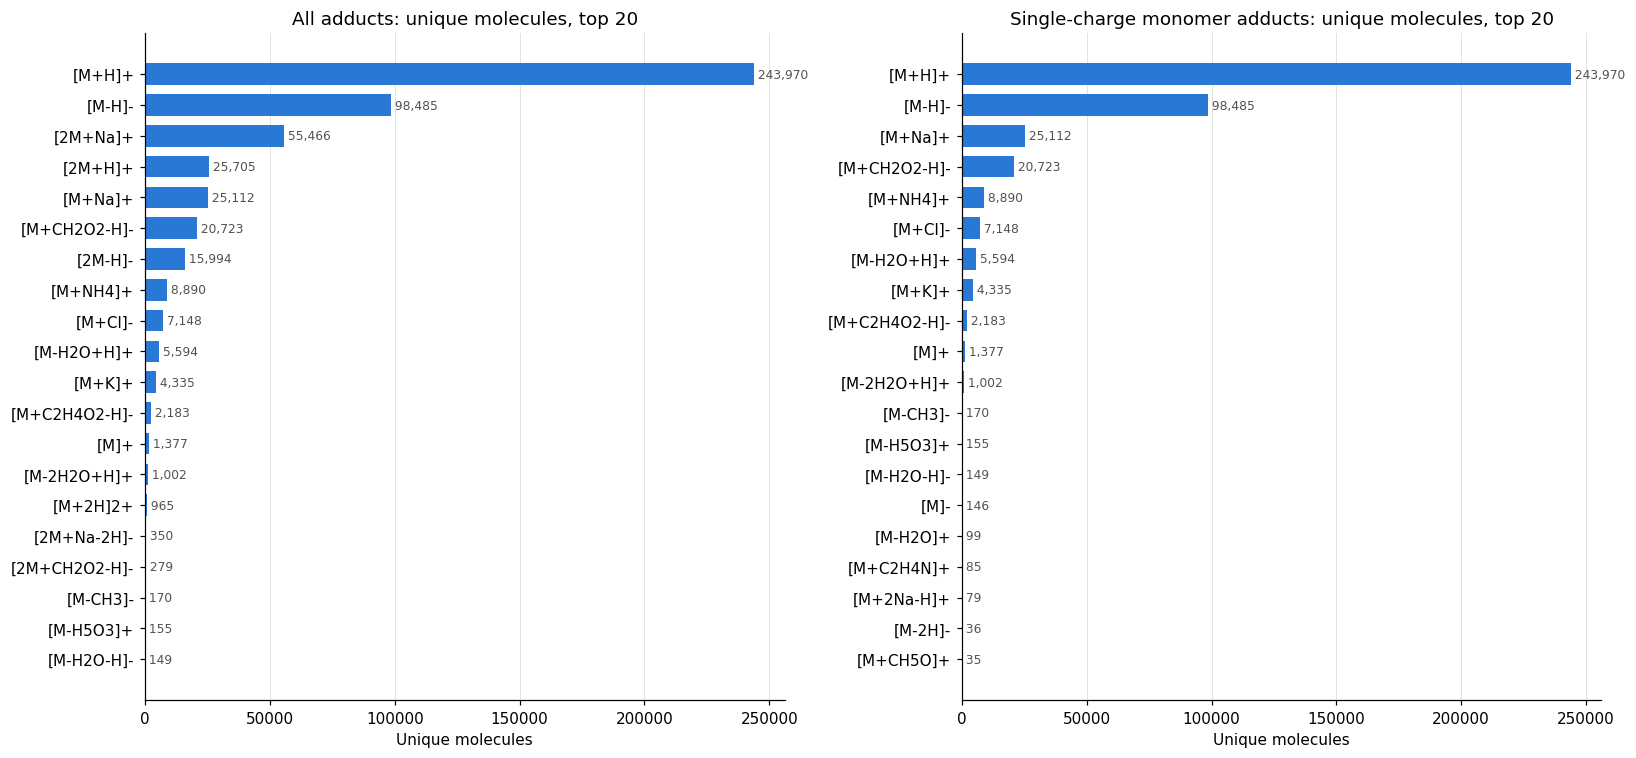

In [6]:
# Unique molecules per adduct: all adducts, then single-charge monomers only
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for ax, (title, sub) in zip(
    axes,
    [("All adducts", df), ("Single-charge monomer adducts", df[df.monomer_1z])],
):
    counts = sub.groupby("adduct")["inchikey14"].nunique().sort_values(ascending=False).head(20)
    ax.barh(counts.index[::-1], counts.values[::-1], color=SERIES[0], height=0.7)
    for y, v in enumerate(counts.values[::-1]):
        ax.text(v, y, f" {v:,}", va="center", fontsize=8, color="#52514e")
    ax.set_xlabel("Unique molecules")
    ax.set_title(f"{title}: unique molecules, top 20")
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### Collision energy

`collision_energy_ev` is already in eV: NCE rows are converted as NCE x precursor m/z / 500
(the project's ACE rule), e.g. NCE 30 at m/z 314 -> 18.8 eV. Rows with unknown units have no
energy.

In [7]:
display(pd.crosstab(df.ingest_lib, df.collision_energy_orig_units).loc[LIB_ORDER])
display(pd.crosstab(df.ingest_lib, df.n_ce.clip(upper=4).map({0: "none", 1: "1", 2: "2", 3: "3", 4: "4+"})).loc[LIB_ORDER])

collision_energy_orig_units,NCE,V,eV,unknown
ingest_lib,,,,
enveda-180,0,0,1153785,0
pluskal_ms2,527581,0,0,0
riken,158807,17038,147110,24216
gnps,0,0,0,220849
massbank,39660,18672,41726,1669
mona,51234,9821,16501,14860
spectraverse,2619,0,1248,47066
msdial,9165,11025,7354,13221
drug_plus,0,0,0,2545


n_ce,1,2,3,4+,none
ingest_lib,,,,,
enveda-180,847063,1942,304780,0,0
pluskal_ms2,352859,3548,82949,88225,0
riken,311875,1649,1967,0,31680
gnps,0,0,0,0,220849
massbank,95273,3983,559,0,1912
mona,72472,722,3477,0,15745
spectraverse,3858,0,0,0,47075
msdial,22490,505,785,0,16985
drug_plus,0,0,0,0,2545


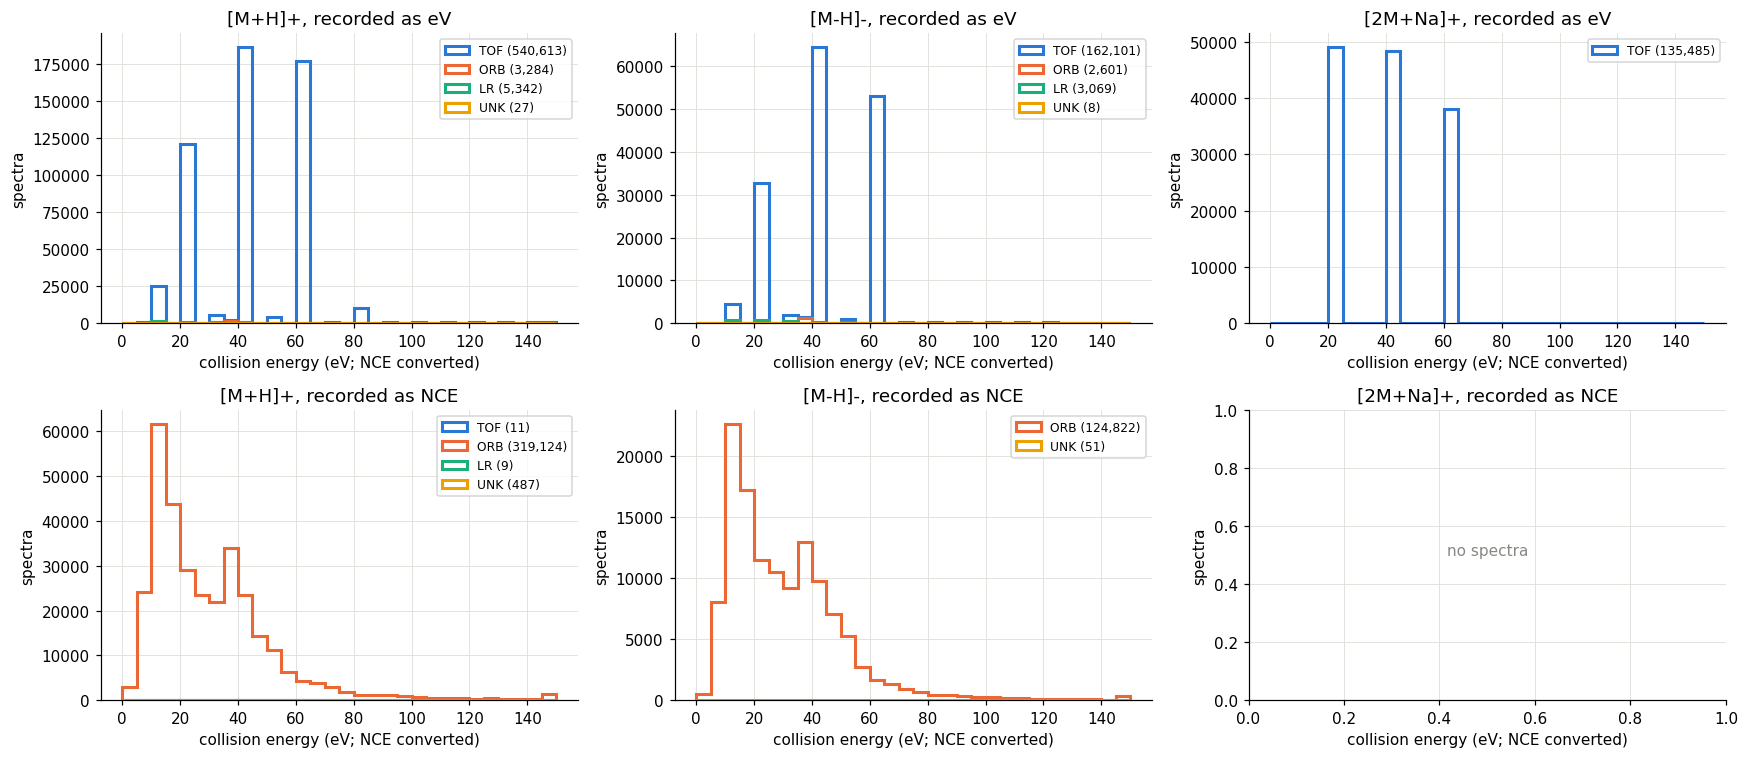

In [8]:
# Single-energy spectra: energy in eV by instrument class, top 3 adducts, split by original unit
single = df[df.n_ce == 1]
top3 = df.adduct.value_counts().head(3).index
bins = np.arange(0, 151, 5)
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for j, adduct in enumerate(top3):
    for i, unit in enumerate(["eV", "NCE"]):
        ax = axes[i, j]
        sub = single[(single.adduct == adduct) & (single.collision_energy_orig_units == unit)]
        for cls in INST_ORDER:
            values = sub.loc[sub.inst_class == cls, "ce_first"].dropna()
            if len(values):
                ax.hist(values.clip(upper=150), bins=bins, histtype="step", linewidth=2,
                        color=INST_COLORS[cls], label=f"{cls} ({len(values):,})")
        ax.set_title(f"{adduct}, recorded as {unit}")
        ax.set_xlabel("collision energy (eV; NCE converted)")
        ax.set_ylabel("spectra")
        if ax.get_legend_handles_labels()[0]:
            ax.legend(fontsize=8)
        else:
            ax.text(0.5, 0.5, "no spectra", transform=ax.transAxes, ha="center", color="#898781")
plt.tight_layout()
plt.show()

In [9]:
# Molecules shared between libraries (InChIKey first block)
sets = {name: set(df.loc[df.ingest_lib == name, "inchikey14"]) for name in LIB_ORDER}
overlap = pd.DataFrame(
    [[len(sets[a] & sets[b]) for b in LIB_ORDER] for a in LIB_ORDER], index=LIB_ORDER, columns=LIB_ORDER
)
libs_per_mol = df.groupby("inchikey14").ingest_lib.nunique()
print(f"molecules in more than one library: {(libs_per_mol > 1).sum():,} / {len(libs_per_mol):,}")
display(overlap)

molecules in more than one library: 28,113 / 275,810


## B. Peak-level checks

From `nist20.ipynb` (peaks above the precursor, low-intensity peaks) and
`nist23_data_quality.ipynb` (peak-position heuristics, same definitions):

- `frac_not_far_above_prec`: fraction of peaks at m/z <= precursor + 1.5
- `n_far_above_prec`: peaks above precursor + 2 Da
- `has_prec_peak`: any peak within 0.02 Da of the precursor
- `intensity_entropy`: -sum p log p over normalized intensities
- `int_frac_above_prec`: intensity above the precursor + one matching tolerance (the
  `filter_above_precursor_peaks` cutoff)

Intensities are base-peak normalized, so the NIST absolute-intensity thresholds become relative
ones here.

In [10]:
peak = df.groupby("ingest_lib").agg(
    median_peaks=("num_peaks", "median"),
    median_peaks_ge_1pct=("n_peaks_1pct", "median"),
    min_rel_int_lt_0p001=("min_rel_int", lambda s: (s < 0.001).mean()),
    min_rel_int_lt_0p01=("min_rel_int", lambda s: (s < 0.01).mean()),
    any_above_prec=("int_frac_above_prec", lambda s: (s > 0).mean()),
    mean_int_above_prec=("int_frac_above_prec", "mean"),
    far_above_prec=("n_far_above_prec", lambda s: (s > 0).mean()),
    median_frac_not_far_above=("frac_not_far_above_prec", "median"),
    has_prec_peak=("has_prec_peak", "mean"),
    median_entropy=("intensity_entropy", "median"),
).loc[LIB_ORDER]
display(peak.round(3))

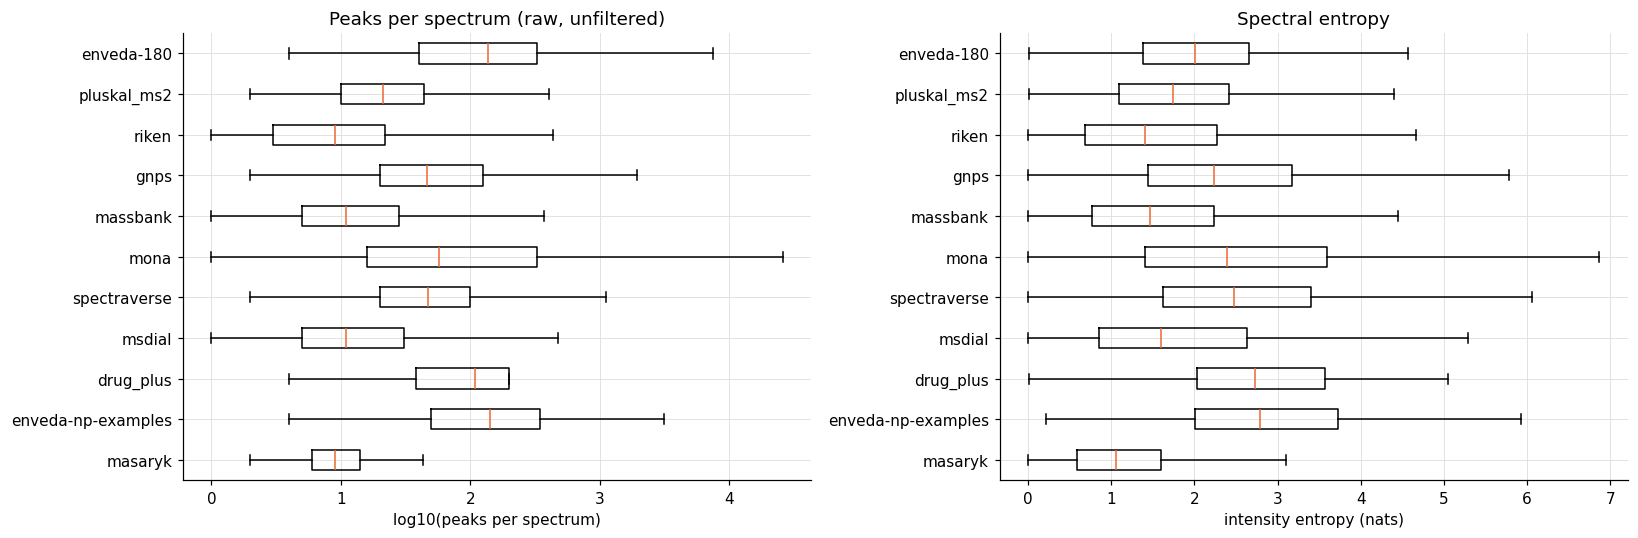

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
data = [np.log10(df.loc[df.ingest_lib == name, "num_peaks"].clip(lower=1)) for name in LIB_ORDER]
ax.boxplot(data, vert=False, tick_labels=LIB_ORDER, showfliers=False, medianprops={"color": SERIES[1]})
ax.set_xlabel("log10(peaks per spectrum)")
ax.set_title("Peaks per spectrum (raw, unfiltered)")
ax.invert_yaxis()
ax = axes[1]
data = [df.loc[df.ingest_lib == name, "intensity_entropy"].dropna() for name in LIB_ORDER]
ax.boxplot(data, vert=False, tick_labels=LIB_ORDER, showfliers=False, medianprops={"color": SERIES[1]})
ax.set_xlabel("intensity entropy (nats)")
ax.set_title("Spectral entropy")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## C. Precursor m/z and formula labels

`prec_calc_ppm` is the reported precursor m/z against the m/z implied by `molecular_formula`
and the adduct (computed for the 21 adducts the stats script maps; dimers use 2M). The
release's own `precursor_error_ppm` is shown for comparison. Integer precursor m/z values
(low-resolution libraries) give large errors by construction.

In [12]:
ppm = df[df.adduct_proj.notna()].copy()
ppm["abs_ppm"] = ppm.prec_calc_ppm.abs()
ppm["integer_prec"] = np.isclose(ppm.precursor_mz, ppm.precursor_mz.round(), atol=1e-6)
ppm["gross"] = (ppm.precursor_mz - ppm.prec_calc_mz).abs() > 0.5
prec = ppm.groupby("ingest_lib").agg(
    spectra=("abs_ppm", "size"),
    median_abs_ppm=("abs_ppm", "median"),
    p99_abs_ppm=("abs_ppm", lambda s: s.quantile(0.99)),
    gt_10ppm=("abs_ppm", lambda s: (s > 10).mean()),
    gt_50ppm=("abs_ppm", lambda s: (s > 50).mean()),
    gt_0p5Da=("gross", "mean"),
    integer_prec=("integer_prec", "mean"),
).loc[LIB_ORDER]
display(prec.round(4))

# The release's precursor_error_ppm is not this quantity: it matches ours only for
# enveda-np-examples, and is near-uncorrelated with it elsewhere. Its definition is unknown.
both = ppm[ppm.precursor_error_ppm.notna()]
display(both.groupby("ingest_lib").apply(
    lambda g: pd.Series({
        "spearman_vs_release": g.prec_calc_ppm.corr(g.precursor_error_ppm, method="spearman"),
        "median_abs_diff_ppm": (g.prec_calc_ppm - g.precursor_error_ppm).abs().median(),
    }),
    include_groups=False,
).loc[[name for name in LIB_ORDER if name in set(both.ingest_lib)]].round(3))

,spearman_vs_release,median_abs_diff_ppm
ingest_lib,,
enveda-180,0.018,1.536
pluskal_ms2,0.020,1.645
riken,-0.280,2.442
gnps,-0.383,1.724
massbank,-0.185,1.942
mona,-0.199,1.829
spectraverse,-0.289,0.713
msdial,0.019,1.488
drug_plus,-0.160,1.708


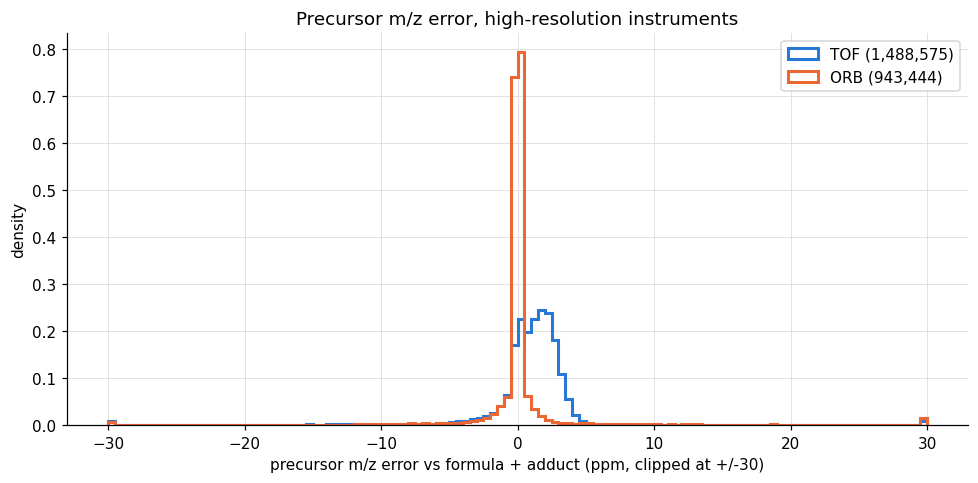

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.linspace(-30, 30, 121)
hr = ppm[ppm.inst_class.isin(["TOF", "ORB"]) & ~ppm.integer_prec]
for cls in ["TOF", "ORB"]:
    values = hr.loc[hr.inst_class == cls, "prec_calc_ppm"].dropna()
    if values.empty:
        continue
    ax.hist(values.clip(-30, 30), bins=bins, histtype="step", linewidth=2,
            color=INST_COLORS[cls], label=f"{cls} ({len(values):,})", density=True)
ax.set_xlabel("precursor m/z error vs formula + adduct (ppm, clipped at +/-30)")
ax.set_ylabel("density")
ax.set_title("Precursor m/z error, high-resolution instruments")
ax.legend()
plt.tight_layout()
plt.show()

### m/z precision

Decimals written for the precursor m/z (all spectra) and the most precise fragment m/z (3,000
sampled spectra per library). Two decimals means 0.01 Da steps, which the tight subformula tier
(2 mDa) cannot match. RIKEN rows labelled plain `QTOF`/`Orbitrap` are split out.

In [14]:
import pyarrow.parquet as pq


def n_decimals(values: np.ndarray, max_decimals: int = 6) -> np.ndarray:
    # Smallest k with |x - round(x, k)| < 1e-7; max_decimals + 1 when none fits.
    fits = np.stack([np.abs(values - np.round(values, k)) < 1e-7 for k in range(max_decimals + 1)])
    return np.where(fits.any(axis=0), fits.argmax(axis=0), max_decimals + 1)


df["lib_group"] = np.where(
    (df.ingest_lib == "riken") & df.instrument_type.isin(["QTOF", "Orbitrap"]),
    "riken (QTOF/Orbitrap label)",
    df.ingest_lib,
)
GROUP_ORDER = LIB_ORDER[:3] + ["riken (QTOF/Orbitrap label)"] + LIB_ORDER[3:]
df["prec_decimals"] = n_decimals(df.precursor_mz.to_numpy())
print("precursor m/z decimals (share of spectra)")
display(pd.crosstab(df.lib_group, df.prec_decimals.clip(upper=5), normalize="index").loc[GROUP_ORDER].round(3))

parquet = pq.ParquetFile(TRAIN_FP)
starts = np.cumsum([0] + [parquet.metadata.row_group(g).num_rows for g in range(parquet.metadata.num_row_groups)])
sample_idx = np.sort(np.concatenate([
    group.sample(min(3000, len(group)), random_state=0).index.to_numpy()
    for _, group in df.groupby("lib_group")
]))
peak_decimals = {}
for g in range(len(starts) - 1):
    local = sample_idx[(sample_idx >= starts[g]) & (sample_idx < starts[g + 1])] - starts[g]
    if not len(local):
        continue
    lists = parquet.read_row_group(g, columns=["ms2_mzs"]).column("ms2_mzs").take(local).to_pylist()
    for row, mzs in zip(local + starts[g], lists):
        peak_decimals[row] = int(n_decimals(np.asarray(mzs)).max()) if len(mzs) else -1
peak_dec = pd.Series(peak_decimals, name="peak_decimals")
print("most precise fragment m/z decimals (share of sampled spectra)")
display(pd.crosstab(df.lib_group.loc[peak_dec.index], peak_dec.clip(upper=5), normalize="index").loc[GROUP_ORDER].round(3))

precursor m/z decimals (share of spectra)


prec_decimals,0,1,2,3,4,5
lib_group,,,,,,
enveda-180,0.000,0.001,0.008,0.091,0.900,0.000
pluskal_ms2,0.000,0.000,0.007,0.089,0.903,0.000
riken,0.046,0.014,0.063,0.194,0.682,0.000
riken (QTOF/Orbitrap label),0.002,0.090,0.854,0.053,0.002,0.000
gnps,0.003,0.014,0.128,0.853,0.001,0.000
massbank,0.055,0.013,0.046,0.084,0.802,0.000
mona,0.027,0.006,0.036,0.185,0.747,0.000
spectraverse,0.000,0.001,0.046,0.464,0.488,0.000
msdial,0.000,0.000,0.007,0.090,0.902,0.000


most precise fragment m/z decimals (share of sampled spectra)


peak_decimals,0,1,2,3,4,5
lib_group,,,,,,
enveda-180,0.000,0.000,0.000,0.000,1.000,0.000
pluskal_ms2,0.000,0.000,0.000,0.000,1.000,0.000
riken,0.028,0.048,0.079,0.839,0.006,0.000
riken (QTOF/Orbitrap label),0.000,0.001,0.013,0.986,0.000,0.000
gnps,0.019,0.001,0.003,0.011,0.966,0.000
massbank,0.027,0.057,0.018,0.008,0.890,0.000
mona,0.002,0.041,0.016,0.015,0.926,0.000
spectraverse,0.000,0.000,0.000,0.049,0.951,0.000
msdial,0.121,0.107,0.107,0.663,0.002,0.000


In [15]:
# Formula and structure labels (one row per normalized SMILES)
print(f"{len(mols):,} normalized SMILES")
summary = pd.Series(
    {
        "RDKit parse fails": (~mols.parse_ok).sum(),
        "RDKit formula != molecular_formula": (mols.parse_ok & ~mols.formula_match).sum(),
        "SMILES with >1 formula label": (mols.n_formula_labels > 1).sum(),
        "multi-component SMILES": (mols.n_components > 1).sum(),
        "nonzero formal charge": (mols.formal_charge.fillna(0) != 0).sum(),
    }
)
display(summary.to_frame("count"))
display(mols[mols.parse_ok & ~mols.formula_match].head(10))
display(df.groupby("ingest_lib").heavy_atoms.describe(percentiles=[0.05, 0.5, 0.95]).loc[LIB_ORDER].round(1))

277,566 normalized SMILES


,count
RDKit parse fails,0
RDKit formula != molecular_formula,0
SMILES with >1 formula label,0
multi-component SMILES,0
nonzero formal charge,626


,normalized_smiles,formula_label,n_formula_labels,parse_ok,formula_rdkit,formal_charge,heavy_atoms,n_components,formula_match


,count,mean,std,min,5%,50%,95%,max
ingest_lib,,,,,,,,
enveda-180,1153785.0,23.3,2.7,18.0,19.0,23.0,28.0,37.0
pluskal_ms2,527581.0,25.6,8.6,6.0,15.0,24.0,40.0,125.0
riken,347171.0,31.2,15.6,3.0,12.0,28.0,62.0,186.0
gnps,220849.0,27.3,13.7,2.0,11.0,25.0,51.0,238.0
massbank,101727.0,23.3,12.4,3.0,10.0,21.0,51.0,125.0
mona,92416.0,26.8,15.5,3.0,10.0,23.0,57.0,156.0
spectraverse,50933.0,47.5,14.4,6.0,21.0,51.0,67.0,71.0
msdial,40765.0,30.7,21.0,3.0,9.0,25.0,71.0,208.0
drug_plus,2545.0,23.9,11.5,2.0,9.0,22.0,43.8,115.0


## D. Subformula coverage (in place of DAG coverage)

A peak is explained when its m/z is within tolerance of a precursor-bounded, nonnegative-RDBE
subformula of the labelled molecule, using the candidate set of
`fragnnet.utils.clean_spectra_utils.filter_subformula_peaks` (charge migration included, so
`[M+Na]+` accepts `[frag+H]+`). Dimers `[2M+X]` are checked as `[M'+X]` with M' = 2M.

- **Instrument tier** (`sf_*`): the project's tolerance per class: ORB 10 ppm with a 200 m/z
  floor (>= 2 mDa); TOF, LR and UNK 20 ppm with a 750 m/z floor (>= 15 mDa).
- **Tight tier** (`*_tight`): ORB tolerance for every instrument.
- **Chance control** (`*_null*`): the same match after shifting every peak by +/-0.05 Da,
  averaged. It measures how much intensity a dense subformula grid explains by accident.

Coverage only means something relative to its chance control. LR spectra are matched at the
QTOF tolerance and are shown for completeness only.

In [16]:
display(pd.crosstab(df.ingest_lib, df.sf_status).loc[LIB_ORDER])
print(f"unsupported adduct strings: {df.loc[df.sf_status == 'unsupported_adduct', 'adduct'].nunique()}, "
      f"covering {(df.sf_status == 'unsupported_adduct').sum():,} spectra")

sf_status,ok,too_large,unsupported_adduct,unsupported_element
ingest_lib,,,,
enveda-180,1153785,0,0,0
pluskal_ms2,526725,6,845,5
riken,345596,106,1469,0
gnps,219011,53,1785,0
massbank,100867,0,860,0
mona,91896,34,486,0
spectraverse,50933,0,0,0
msdial,39367,11,1387,0
drug_plus,2537,0,8,0


unsupported adduct strings: 100, covering 6,840 spectra


In [17]:
ok = df[df.sf_status == "ok"].copy()
ok["excess_tight"] = ok.sf_int_frac_tight - ok.sf_int_frac_null_tight
SF_COLS = {
    "sf_int_frac": "median",
    "sf_int_frac_null": "median",
    "sf_int_frac_tight": "median",
    "sf_int_frac_null_tight": "median",
    "sf_int_frac_1pct": "median",
    "sf_int_frac_iso": "median",
    "sf_base_explained": "mean",
    "sf_base_explained_tight": "mean",
}
for label, sub in [("Single-charge monomers", ok[ok.monomer_1z]), ("Dimers", ok[ok.is_dimer])]:
    table = sub.groupby(["ingest_lib", "inst_class"]).agg(spectra=("adduct", "size"), **{k: (k, v) for k, v in SF_COLS.items()})
    table = table[table.spectra >= 200]
    print(label)
    display(table.round(3))

Single-charge monomers


Dimers


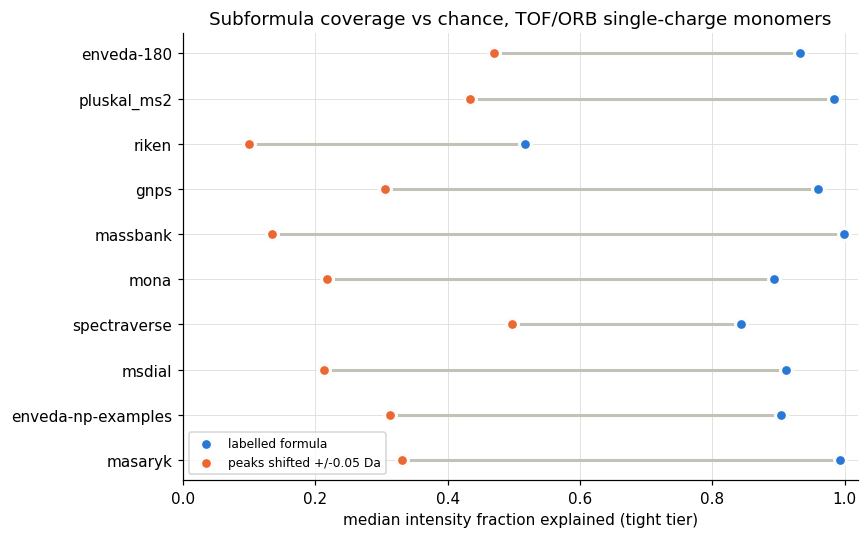

In [18]:
# True formula vs chance control, tight tier, HR monomers, per library
hr_mono = ok[ok.monomer_1z & ok.inst_class.isin(["TOF", "ORB"])]
med = hr_mono.groupby("ingest_lib")[["sf_int_frac_tight", "sf_int_frac_null_tight"]].median()
med = med.reindex([name for name in LIB_ORDER if name in med.index])
fig, ax = plt.subplots(figsize=(8, 5))
y = np.arange(len(med))
ax.hlines(y, med.sf_int_frac_null_tight, med.sf_int_frac_tight, color="#c3c2b7", linewidth=2)
ax.scatter(med.sf_int_frac_tight, y, s=60, color=TRUE_COLOR, label="labelled formula", zorder=3,
           edgecolors="#fcfcfb", linewidths=2)
ax.scatter(med.sf_int_frac_null_tight, y, s=60, color=NULL_COLOR, label="peaks shifted +/-0.05 Da",
           zorder=3, edgecolors="#fcfcfb", linewidths=2)
ax.set_yticks(y, med.index)
ax.invert_yaxis()
ax.set_xlim(0, 1.02)
ax.set_xlabel("median intensity fraction explained (tight tier)")
ax.set_title("Subformula coverage vs chance, TOF/ORB single-charge monomers")
ax.legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

In [19]:
# By adduct, HR monomers
by_adduct = hr_mono.groupby("adduct").agg(
    spectra=("adduct", "size"),
    sf_int_frac=("sf_int_frac", "median"),
    sf_int_frac_null=("sf_int_frac_null", "median"),
    sf_int_frac_tight=("sf_int_frac_tight", "median"),
    sf_int_frac_null_tight=("sf_int_frac_null_tight", "median"),
    base_explained_tight=("sf_base_explained_tight", "mean"),
).sort_values("spectra", ascending=False).head(15)
display(by_adduct.round(3))

### Coverage tiers and the peak-position heuristics

`nist23_data_quality.ipynb` binned spectra by DAG `wrecall`; here the bins are tight-tier
subformula coverage, on TOF/ORB single-charge monomers.

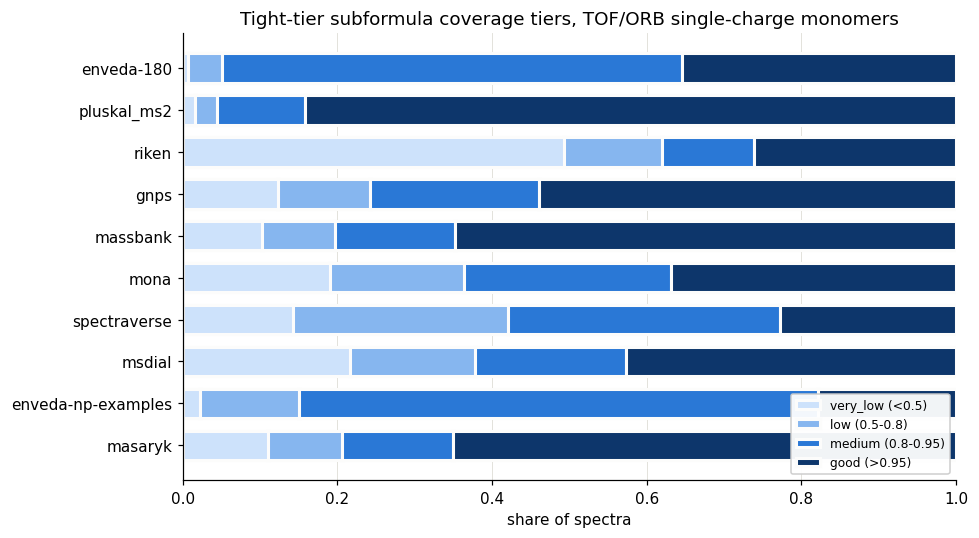

sf_tier,very_low (<0.5),low (0.5-0.8),medium (0.8-0.95),good (>0.95)
ingest_lib,,,,
enveda-180,0.007,0.044,0.594,0.355
pluskal_ms2,0.016,0.028,0.113,0.843
riken,0.494,0.127,0.118,0.262
gnps,0.123,0.119,0.219,0.539
massbank,0.102,0.094,0.156,0.648
mona,0.190,0.173,0.268,0.369
spectraverse,0.143,0.279,0.351,0.228
msdial,0.216,0.162,0.195,0.427
enveda-np-examples,0.022,0.128,0.671,0.178


In [20]:
TIER_ORDER = ["very_low (<0.5)", "low (0.5-0.8)", "medium (0.8-0.95)", "good (>0.95)"]
TIER_COLORS = dict(zip(TIER_ORDER, ["#cde2fb", "#86b6ef", "#2a78d6", "#0d366b"]))
hr_mono = hr_mono.assign(
    sf_tier=pd.cut(hr_mono.sf_int_frac_tight, bins=[-0.001, 0.5, 0.8, 0.95, 1.001], labels=TIER_ORDER)
)
tiers = pd.crosstab(hr_mono.ingest_lib, hr_mono.sf_tier, normalize="index")[TIER_ORDER]
tiers = tiers.reindex([name for name in LIB_ORDER if name in tiers.index])

fig, ax = plt.subplots(figsize=(9, 5))
left = np.zeros(len(tiers))
for tier in TIER_ORDER:
    ax.barh(tiers.index, tiers[tier], left=left, color=TIER_COLORS[tier], label=tier,
            edgecolor="#fcfcfb", linewidth=2, height=0.7)
    left += tiers[tier].to_numpy()
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("share of spectra")
ax.set_title("Tight-tier subformula coverage tiers, TOF/ORB single-charge monomers")
ax.legend(fontsize=8, loc="lower right", framealpha=0.95)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
display(tiers.round(3))

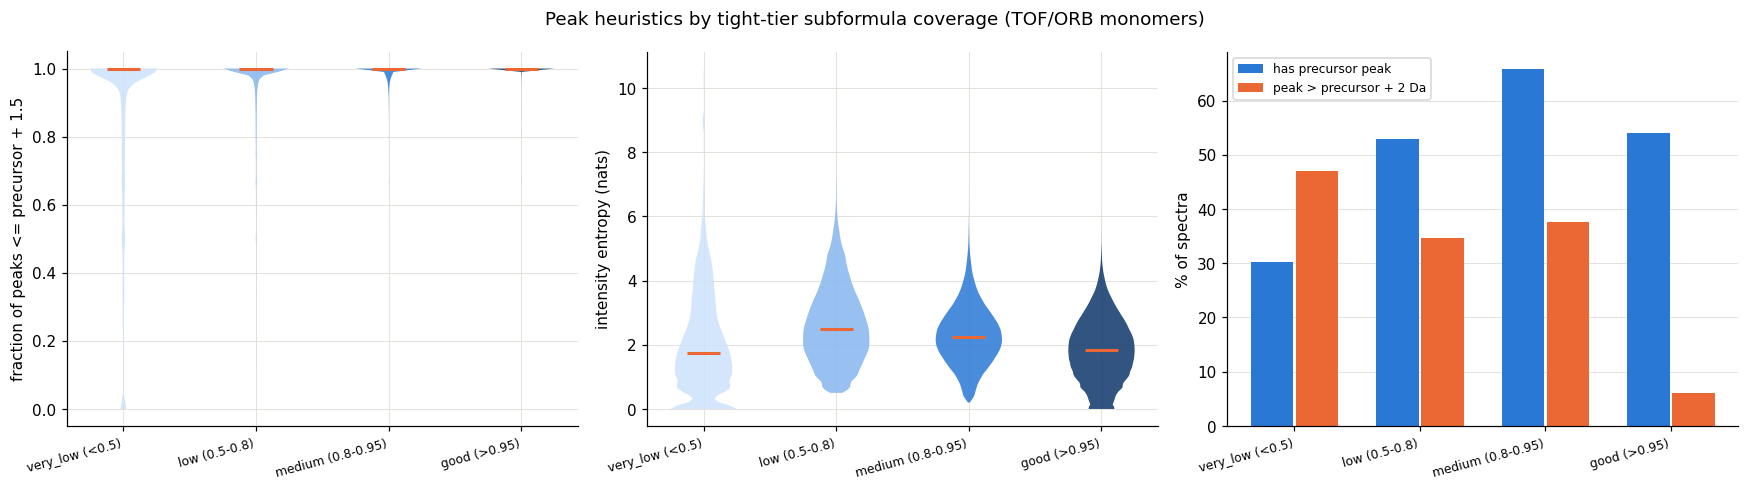

sf_tier
very_low (<0.5)       228009
low (0.5-0.8)         152836
medium (0.8-0.95)     685546
good (>0.95)         1035300


In [21]:
# nist23_data_quality cell D, with subformula tiers in place of DAG tiers
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col, ylabel in [
    (axes[0], "frac_not_far_above_prec", "fraction of peaks <= precursor + 1.5"),
    (axes[1], "intensity_entropy", "intensity entropy (nats)"),
]:
    data = [hr_mono.loc[hr_mono.sf_tier == t, col].dropna().to_numpy() for t in TIER_ORDER]
    parts = ax.violinplot(data, positions=range(len(TIER_ORDER)), showmedians=True, showextrema=False)
    for body, tier in zip(parts["bodies"], TIER_ORDER):
        body.set_facecolor(TIER_COLORS[tier])
        body.set_alpha(0.85)
    parts["cmedians"].set_color(SERIES[1])
    parts["cmedians"].set_linewidth(2)
    ax.set_xticks(range(len(TIER_ORDER)), TIER_ORDER, rotation=15, ha="right", fontsize=8)
    ax.set_ylabel(ylabel)
ax = axes[2]
x = np.arange(len(TIER_ORDER))
grouped = hr_mono.groupby("sf_tier", observed=True)
ax.bar(x - 0.18, grouped.has_prec_peak.mean().reindex(TIER_ORDER) * 100, 0.34,
       color=SERIES[0], label="has precursor peak")
ax.bar(x + 0.18, grouped.n_far_above_prec.apply(lambda s: (s > 0).mean()).reindex(TIER_ORDER) * 100,
       0.34, color=SERIES[1], label="peak > precursor + 2 Da")
ax.set_xticks(x, TIER_ORDER, rotation=15, ha="right", fontsize=8)
ax.set_ylabel("% of spectra")
ax.legend(fontsize=8)
ax.grid(axis="x", visible=False)
fig.suptitle("Peak heuristics by tight-tier subformula coverage (TOF/ORB monomers)")
plt.tight_layout()
plt.show()
print(hr_mono.sf_tier.value_counts().reindex(TIER_ORDER).to_string())

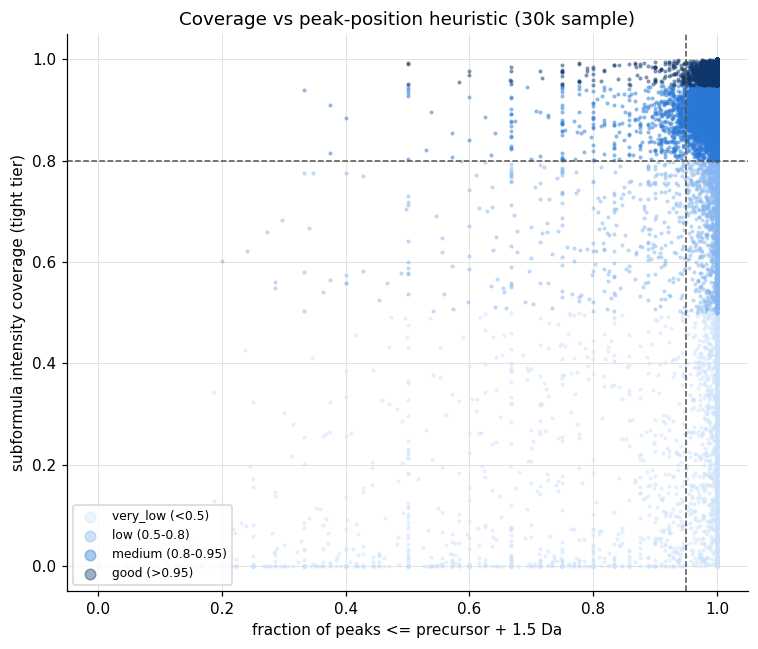

few peaks above precursor, high coverage      1,670,294   79.5%
few peaks above precursor, LOW coverage         274,703   13.1%
many peaks above precursor, high coverage        50,552    2.4%
many peaks above precursor, low coverage        106,142    5.1%


In [22]:
# nist23_data_quality cell C: quadrant, peak-position heuristic vs subformula coverage
THRESHOLD_X, THRESHOLD_Y = 0.95, 0.8
plot_df = hr_mono[["frac_not_far_above_prec", "sf_int_frac_tight", "sf_tier"]].dropna()
sample = plot_df.sample(min(30_000, len(plot_df)), random_state=42)
fig, ax = plt.subplots(figsize=(7, 6))
for tier in TIER_ORDER:
    sub = sample[sample.sf_tier == tier]
    ax.scatter(sub.frac_not_far_above_prec, sub.sf_int_frac_tight, s=3, alpha=0.4,
               color=TIER_COLORS[tier], label=tier)
ax.axvline(THRESHOLD_X, color="#52514e", lw=1, ls="--")
ax.axhline(THRESHOLD_Y, color="#52514e", lw=1, ls="--")
ax.set_xlabel("fraction of peaks <= precursor + 1.5 Da")
ax.set_ylabel("subformula intensity coverage (tight tier)")
ax.set_title("Coverage vs peak-position heuristic (30k sample)")
ax.legend(fontsize=8, markerscale=4, loc="lower left")
plt.tight_layout()
plt.show()
x_ok = plot_df.frac_not_far_above_prec > THRESHOLD_X
y_ok = plot_df.sf_int_frac_tight > THRESHOLD_Y
n = len(plot_df)
for name, mask in [
    ("few peaks above precursor, high coverage", x_ok & y_ok),
    ("few peaks above precursor, LOW coverage", x_ok & ~y_ok),
    ("many peaks above precursor, high coverage", ~x_ok & y_ok),
    ("many peaks above precursor, low coverage", ~x_ok & ~y_ok),
]:
    print(f"{name:45s} {mask.sum():9,}  {mask.mean() * 100:5.1f}%")

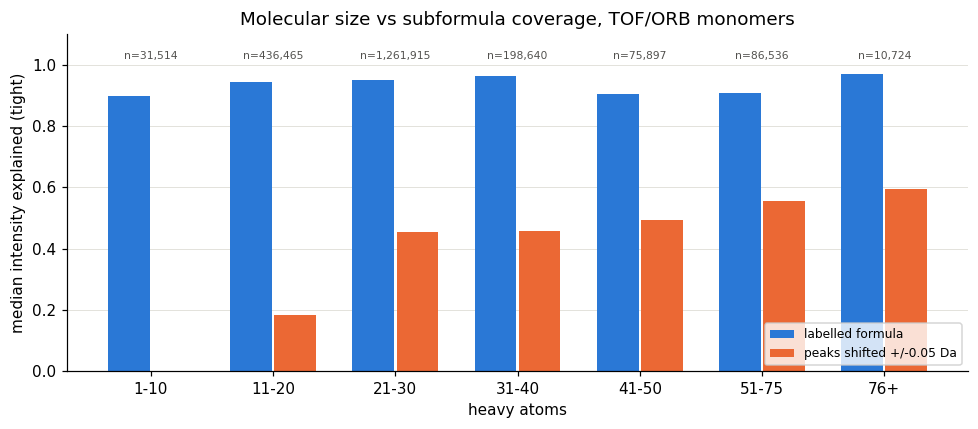

,spectra,true,chance
atom_bin,,,
1-10,31514,0.900,0.000
11-20,436465,0.945,0.183
21-30,1261915,0.951,0.453
31-40,198640,0.962,0.457
41-50,75897,0.903,0.492
51-75,86536,0.909,0.557
76+,10724,0.969,0.594


In [23]:
# nist23_data_quality cell E: molecular size vs coverage; chance coverage grows with size
BINS = [0, 10, 20, 30, 40, 50, 75, 150]
LABELS = ["1-10", "11-20", "21-30", "31-40", "41-50", "51-75", "76+"]
size = hr_mono.assign(atom_bin=pd.cut(hr_mono.heavy_atoms, bins=BINS, labels=LABELS))
size_stats = size.groupby("atom_bin", observed=True).agg(
    spectra=("adduct", "size"),
    true=("sf_int_frac_tight", "median"),
    chance=("sf_int_frac_null_tight", "median"),
)
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(size_stats))
ax.bar(x - 0.18, size_stats["true"], 0.34, color=TRUE_COLOR, label="labelled formula")
ax.bar(x + 0.18, size_stats["chance"], 0.34, color=NULL_COLOR, label="peaks shifted +/-0.05 Da")
for xi, n_spec in zip(x, size_stats.spectra):
    ax.text(xi, 1.02, f"n={n_spec:,}", ha="center", fontsize=7, color="#52514e")
ax.set_xticks(x, size_stats.index)
ax.set_xlabel("heavy atoms")
ax.set_ylabel("median intensity explained (tight)")
ax.set_ylim(0, 1.1)
ax.set_title("Molecular size vs subformula coverage, TOF/ORB monomers")
ax.legend(fontsize=8, loc="lower right")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
display(size_stats.round(3))

### Spectra the labelled formula does not explain

Flag: TOF/ORB single-charge monomer, tight-tier base peak unexplained, and tight coverage no more
than 0.1 above its chance control. These are candidates for wrong structure, adduct or precursor
labels, or for contamination; the flag alone does not prove a spectrum is bad.

In [24]:
hr_mono = hr_mono.assign(
    suspect=~hr_mono.sf_base_explained_tight
    & (hr_mono.sf_int_frac_tight - hr_mono.sf_int_frac_null_tight <= 0.1)
)
suspect_rate = hr_mono.groupby("ingest_lib").agg(
    spectra=("suspect", "size"),
    suspect=("suspect", "sum"),
    suspect_rate=("suspect", "mean"),
    base_unexplained_tight=("sf_base_explained_tight", lambda s: 1 - s.mean()),
)
suspect_rate = suspect_rate.reindex([name for name in LIB_ORDER if name in suspect_rate.index])
display(suspect_rate.round(4))
cols = ["ingest_lib", "adduct", "inst_class", "precursor_mz", "prec_calc_ppm", "num_peaks",
        "sf_int_frac_tight", "sf_int_frac_null_tight", "normalized_smiles"]
display(hr_mono[hr_mono.suspect].sample(12, random_state=0)[cols].round(3))

,spectra,suspect,suspect_rate,base_unexplained_tight
ingest_lib,,,,
enveda-180,822361,1067,0.0013,0.0042
pluskal_ms2,526725,4280,0.0081,0.0184
riken,312269,125851,0.403,0.4755
gnps,205345,14365,0.07,0.1122
massbank,92032,5717,0.0621,0.1026
mona,85829,8660,0.1009,0.1749
spectraverse,41367,4258,0.1029,0.1562
msdial,14224,1937,0.1362,0.1834
enveda-np-examples,1184,6,0.0051,0.0194


### Where the unexplained spectra are: RIKEN labels and Na/K adducts

RIKEN rows labelled plain `QTOF` or `Orbitrap` carry two-decimal precursors, a 10-80 eV ladder
and only `[M+H]+`/`[M+Na]+`; its other labels (`LC-ESI-QFT`, `LC-ESI-ITFT`, ...) look like the
rest of the data. Sodium and potassium adducts are split by library because their low coverage
is concentrated in a few sources.

In [25]:
COVERAGE_AGG = dict(
    spectra=("adduct", "size"),
    sf_int_frac=("sf_int_frac", "median"),
    sf_int_frac_null=("sf_int_frac_null", "median"),
    tight=("sf_int_frac_tight", "median"),
    tight_null=("sf_int_frac_null_tight", "median"),
    base_explained_tight=("sf_base_explained_tight", "mean"),
    median_abs_prec_ppm=("prec_calc_ppm", lambda s: s.abs().median()),
    le_3_peaks=("num_peaks", lambda s: (s <= 3).mean()),
)
riken = hr_mono[hr_mono.ingest_lib == "riken"]
print("RIKEN, TOF/ORB monomers, by instrument label")
display(riken.groupby("instrument_type").agg(**COVERAGE_AGG).sort_values("spectra", ascending=False).head(8).round(3))
print("RIKEN, by |precursor error|")
display(riken.groupby(pd.cut(riken.prec_calc_ppm.abs(), [0, 5, 10, 20, 50, np.inf]), observed=True).agg(**COVERAGE_AGG).round(3))
for adduct in ["[M+Na]+", "[M+K]+"]:
    print(adduct, "TOF/ORB, by library")
    table = hr_mono[hr_mono.adduct == adduct].groupby(["ingest_lib", "inst_class"]).agg(**COVERAGE_AGG)
    display(table[table.spectra >= 100].round(3))

RIKEN, TOF/ORB monomers, by instrument label


,spectra,sf_int_frac,sf_int_frac_null,tight,tight_null,base_explained_tight,median_abs_prec_ppm,le_3_peaks
instrument_type,,,,,,,,
QTOF,125916,0.582,0.397,0.075,0.070,0.314,5.539,0.396
Orbitrap,97425,0.521,0.043,0.521,0.043,0.524,6.569,0.262
ESI-QFT,28224,0.716,0.232,0.716,0.232,0.634,0.063,0.007
LC-ESI-QTOF,27241,0.991,0.563,0.885,0.174,0.876,0.138,0.117
LC-ESI-QFT,16184,1.000,0.149,1.000,0.149,0.975,0.109,0.177
LC-ESI-ITFT,12545,1.000,0.317,1.000,0.317,0.965,0.114,0.223
Maxis II HD Q-TOF Bruker,1528,0.944,0.738,0.706,0.272,0.857,0.718,0.007
qTof,1276,0.939,0.534,0.578,0.148,0.701,2.839,0.051


RIKEN, by |precursor error|


,spectra,sf_int_frac,sf_int_frac_null,tight,tight_null,base_explained_tight,median_abs_prec_ppm,le_3_peaks
prec_calc_ppm,,,,,,,,
"(0.0, 5.0]",181972,0.924,0.308,0.766,0.168,0.631,0.752,0.234
"(5.0, 10.0]",58977,0.548,0.222,0.239,0.082,0.405,7.142,0.313
"(10.0, 20.0]",48852,0.492,0.102,0.135,0.021,0.364,13.025,0.328
"(20.0, 50.0]",14069,0.176,0.002,0.023,0.000,0.29,24.882,0.322
"(50.0, inf]",8349,0.406,0.202,0.167,0.072,0.379,83337.793,0.393


[M+Na]+ TOF/ORB, by library


[M+K]+ TOF/ORB, by library


spectra  sf_int_frac  sf_int_frac_null  tight  tight_null  base_explained_tight  median_abs_prec_ppm  le_3_peaks
ingest_lib   inst_class                                                                                                                  
enveda-180   TOF            1084        0.957             0.779  0.812       0.455                 0.921                1.996       0.000
gnps         ORB            4538        0.430             0.233  0.430       0.233                 0.391                0.599       0.000
             TOF            1778        0.801             0.630  0.360       0.238                 0.389                2.203       0.103
mona         ORB            4921        0.418             0.227  0.418       0.227                 0.372                0.060       0.000
riken        ORB            5178        0.419             0.209  0.419       0.209                 0.376                0.061       0.012
spectraverse ORB             602        0.372             0.191  0.372       0.191                 0.257                0.130       0.000
             TOF             124        0.726             0.678  0.370       0.266                 0.371                1.389       0.040

In [26]:
# Unexplained base peaks: an m/z that recurs across unrelated molecules is background or a
# cluster ion, not a fragment. 400 sampled spectra per (library, adduct) group, ORB only.
unexplained = hr_mono[(hr_mono.inst_class == "ORB") & ~hr_mono.sf_base_explained_tight]
sampled = pd.concat(
    [g.sample(min(400, len(g)), random_state=0) for _, g in unexplained.groupby(["ingest_lib", "adduct"]) if len(g) >= 100]
)
base_mz = {}
for g in range(len(starts) - 1):
    local = np.sort(sampled.index.to_numpy())
    local = local[(local >= starts[g]) & (local < starts[g + 1])] - starts[g]
    if not len(local):
        continue
    table = parquet.read_row_group(g, columns=["ms2_mzs", "ms2_normalized_intensities"])
    mz_lists = table.column("ms2_mzs").take(local).to_pylist()
    int_lists = table.column("ms2_normalized_intensities").take(local).to_pylist()
    for row, mzs, ints in zip(local + starts[g], mz_lists, int_lists):
        base_mz[row] = mzs[int(np.argmax(ints))]
sampled = sampled.assign(base_mz=pd.Series(base_mz).round(2))
recurring = sampled.groupby("base_mz").agg(
    spectra=("adduct", "size"),
    molecules=("inchikey14", "nunique"),
    adducts=("adduct", lambda s: ", ".join(s.value_counts().index[:3])),
    libraries=("ingest_lib", lambda s: ", ".join(s.value_counts().index[:3])),
).sort_values("molecules", ascending=False)
print(f"{len(sampled):,} sampled ORB spectra with an unexplained base peak")
display(recurring.head(12))

13,243 sampled ORB spectra with an unexplained base peak


,spectra,molecules,adducts,libraries
base_mz,,,,
173.54,437,306,"[M+CH2O2-H]-, [M+Cl]-, [M-H]-","pluskal_ms2, gnps"
61.01,299,188,"[M+Na]+, [M+NH4]+, [M+K]+","mona, spectraverse, gnps"
79.02,275,176,"[M+H]+, [M+Na]+, [M-H2O+H]+","pluskal_ms2, mona, spectraverse"
91.06,290,152,"[M+K]+, [M+NH4]+, [M+Na]+","mona, gnps, spectraverse"
240.91,194,134,"[M+K]+, [M+Na]+, [M+NH4]+","spectraverse, mona, gnps"
98.98,219,132,"[M+NH4]+, [M+H]+, [M+K]+","mona, gnps, spectraverse"
61.99,182,110,"[M-H]-, [M+Cl]-, [M+CH2O2-H]-","mona, pluskal_ms2, riken"
96.96,177,109,"[M-H]-, [M+Cl]-, [M+CH2O2-H]-","riken, mona, gnps"
153.96,104,70,"[M+NH4]+, [M+K]+, [M+Na]+","mona, gnps, riken"


## E. Duplicates

From `scripts/debug/casmi_enveda/casmi26_train_duplicates.py` (writes `duplicates/` under the stats
directory):

```bash
PYTHONPATH=src:. python scripts/debug/casmi_enveda/casmi26_train_duplicates.py \
    --out_dp output/casmi26_train_check_2026_10_05/duplicates --workers 8
```

- **Exact copies:** byte-identical peak arrays (m/z and intensity), whatever the labels.
- **Near-duplicates:** the Spectraverse dedup rule (`docs/plans/masster/spectraverse_dedup_plan.md`,
  user decisions 2026-10-04):
  - same molecule (InChIKey first block) and adduct;
  - instrument class and collision energy match, and a missing value matches anything;
  - Hungarian cosine at 5 ppm (at least 1 mDa) above 0.99.

  `same` edges form clusters that keep the spectrum with the most peaks. A `wildcard` edge
  (matched only through a missing value) drops the less-specified spectrum.
- **Edge types:** a median |m/z difference| of 0 over matched peaks means the same m/z list.
  Above 0 it is an independent acquisition (a replicate), which the rule also counts.

In [27]:
DUP_DP = STATS_DP / "duplicates"
dup = pd.read_parquet(DUP_DP / "casmi26_train_dup_clusters.parquet")
edges = pd.read_parquet(DUP_DP / "casmi26_train_dup_edges.parquet")
if not np.array_equal(dup["row"].to_numpy(), np.arange(len(df))):
    raise ValueError("Duplicate table is not aligned with train.parquet")
df["copy_key"] = dup["copy_key"].to_numpy()
df["dup_kept"] = dup["kept"].to_numpy()
df["dup_cluster_size"] = dup["cluster_size"].to_numpy()
df["wildcard_loser"] = dup["wildcard_loser"].to_numpy()

# Exact copies
copies = df.groupby("copy_key").agg(
    n=("adduct", "size"),
    libraries=("ingest_lib", "nunique"),
    molecules=("inchikey14", "nunique"),
    adducts=("adduct", "nunique"),
)
multi = copies[copies.n > 1]
df["n_exact_copies"] = df["copy_key"].map(copies["n"])
print(f"spectra with a byte-identical twin: {(df.n_exact_copies > 1).sum():,} "
      f"in {len(multi):,} groups; redundant copies: {(multi.n - 1).sum():,}")
print(f"  groups spanning >1 library: {(multi.libraries > 1).sum():,}; "
      f">1 molecule (label conflict): {(multi.molecules > 1).sum():,}; >1 adduct: {(multi.adducts > 1).sum():,}")

spectra with a byte-identical twin: 91,946 in 40,600 groups; redundant copies: 51,346
  groups spanning >1 library: 32,541; >1 molecule (label conflict): 6,805; >1 adduct: 5,719


In [28]:
# Label conflicts: one byte-identical spectrum filed under several molecules. One- and two-peak
# spectra coincide by chance; with >= 5 peaks the same acquisition carries two structures, usually
# near-isobaric precursors (co-isolated compounds), so at least one label is wrong.
conflict = multi[multi.molecules > 1].copy()
conflict["num_peaks"] = df.groupby("copy_key")["num_peaks"].first().reindex(conflict.index)
conflict["prec_span_da"] = df.groupby("copy_key")["precursor_mz"].agg(lambda s: s.max() - s.min()).reindex(conflict.index)
conflict["peaks"] = pd.cut(conflict.num_peaks, [0, 2, 4, np.inf], labels=["1-2", "3-4", ">=5"])
conflict_rows = df[df.copy_key.isin(conflict.index)].assign(peaks=lambda d: d.copy_key.map(conflict.peaks))
display(pd.crosstab(conflict_rows.ingest_lib, conflict_rows.peaks, margins=True))
real = conflict[conflict.peaks == ">=5"]
print(f">=5-peak conflict groups: {len(real):,}; precursor m/z within 0.01 Da: "
      f"{(real.prec_span_da <= 0.01).mean():.1%}; same formula: {(df[df.copy_key.isin(real.index)].groupby('copy_key').molecular_formula.nunique() == 1).mean():.1%}")
cols = ["ingest_lib", "adduct", "precursor_mz", "molecular_formula", "num_peaks", "normalized_smiles"]
for key in real.sample(3, random_state=1).index:
    display(df.loc[df.copy_key == key, cols])

peaks,1-2,3-4,>=5,All
ingest_lib,,,,
gnps,152,13,270,435
masaryk,0,0,2,2
massbank,455,7,18,480
mona,15,6,49,70
msdial,508,22,76,606
pluskal_ms2,70,154,3549,3773
riken,18425,36,99,18560
spectraverse,24,0,30,54
All,19649,238,4093,23980


>=5-peak conflict groups: 2,022; precursor m/z within 0.01 Da: 95.5%; same formula: 3.0%


,ingest_lib,adduct,precursor_mz,molecular_formula,num_peaks,normalized_smiles
1629099,pluskal_ms2,[M+Na]+,348.1683,C19H23N3O2,10,O=C(NCC1(C(O)c2ccccc2)CC1)c1n[nH]c2c1CCCC2
1784179,pluskal_ms2,[M+H]+,348.1666,C16H21N5O4,10,COc1ncc(C)cc1NC(=O)N1CC(OC)CC1c1nnc(C)o1


,ingest_lib,adduct,precursor_mz,molecular_formula,num_peaks,normalized_smiles
1753256,pluskal_ms2,[M+Cl]-,364.1182,C16H19N5O3,49,COc1nc(OC)nc(N2CCN(Cc3ccccc3)C(=O)C2)n1
1913333,pluskal_ms2,[M+CH2O2-H]-,364.1202,C17H18FNO4,49,COc1ccc(C(=O)NCC2(O)CCCc3occc32)cc1F


,ingest_lib,adduct,precursor_mz,molecular_formula,num_peaks,normalized_smiles
1925069,pluskal_ms2,[M-H]-,264.0700,C13H15NO3S,9,CC(C)(NC(=O)C1CSc2ccccc21)C(=O)O
1983889,pluskal_ms2,[M+CH2O2-H]-,264.0689,C9H11F2NO3,9,CC(C)(C)c1nc(C(F)F)c(C(=O)O)o1


In [29]:
# Near-duplicate edges by library pair and edge type
lib_of = df["ingest_lib"].to_numpy()
edges["lib_a"], edges["lib_b"] = lib_of[edges.spec_a], lib_of[edges.spec_b]
edges["pair"] = np.where(edges.lib_a <= edges.lib_b, edges.lib_a + " ~ " + edges.lib_b, edges.lib_b + " ~ " + edges.lib_a)
edges["same_mz_list"] = edges.median_dmz == 0
print(f"{len(edges):,} near-duplicate edges: {(edges.kind == 'same').sum():,} same, "
      f"{(edges.kind == 'wildcard').sum():,} wildcard; same m/z list {edges.same_mz_list.mean():.1%}")
display(
    edges.groupby("pair").agg(
        edges=("kind", "size"),
        same_share=("kind", lambda s: (s == "same").mean()),
        same_mz_list=("same_mz_list", "mean"),
        median_cos=("cos_5ppm", "median"),
    ).sort_values("edges", ascending=False).head(20).round(3)
)

1,042,818 near-duplicate edges: 702,963 same, 339,855 wildcard; same m/z list 44.9%


In [30]:
# What the rule would drop, per library
dropped = df.groupby("ingest_lib").agg(
    spectra=("adduct", "size"),
    has_exact_twin=("n_exact_copies", lambda s: (s > 1).mean()),
    dropped=("dup_kept", lambda s: (~s).sum()),
    dropped_share=("dup_kept", lambda s: (~s).mean()),
    wildcard_losers=("wildcard_loser", "sum"),
).loc[LIB_ORDER]
total = pd.DataFrame(
    {"spectra": [len(df)], "has_exact_twin": [(df.n_exact_copies > 1).mean()],
     "dropped": [(~df.dup_kept).sum()], "dropped_share": [(~df.dup_kept).mean()],
     "wildcard_losers": [df.wildcard_loser.sum()]},
    index=["all"],
)
display(pd.concat([dropped, total]).round(3))
kept = df[df.dup_kept]
print(f"after the rule: {len(kept):,} spectra, {kept.inchikey14.nunique():,} molecules "
      f"(before {df.inchikey14.nunique():,})")

,spectra,has_exact_twin,dropped,dropped_share,wildcard_losers
enveda-180,1153785,0.000,2832,0.002,0
pluskal_ms2,527581,0.012,106881,0.203,0
riken,347171,0.141,148556,0.428,15877
gnps,220849,0.021,114817,0.520,89041
massbank,101727,0.009,9422,0.093,160
mona,92416,0.007,29594,0.320,999
spectraverse,50933,0.002,7045,0.138,1180
msdial,40765,0.749,26783,0.657,8150
drug_plus,2545,0.000,289,0.114,288
enveda-np-examples,1184,0.000,2,0.002,0


after the rule: 2,093,256 spectra, 275,810 molecules (before 275,810)


In [31]:
# Dropped spectra by what links them to their kept twin
loser_edges = pd.concat([
    edges.loc[edges.kind == "wildcard"].assign(loser_row=lambda e: e.loser),
    edges.loc[edges.kind == "same"].melt(
        id_vars=["cos_5ppm", "median_dmz", "kind", "same_mz_list"], value_vars=["spec_a", "spec_b"], value_name="loser_row"
    ),
])
loser_edges = loser_edges[~df.dup_kept.to_numpy()[loser_edges.loser_row.to_numpy()]]
first_edge = loser_edges.sort_values("same_mz_list", ascending=False).drop_duplicates("loser_row")
how = pd.Series(
    np.where(
        df.n_exact_copies.to_numpy()[first_edge.loser_row] > 1, "byte-identical twin exists",
        np.where(first_edge.same_mz_list, "same m/z list, different intensities", "independent acquisition (replicate)"),
    ),
    index=first_edge.loser_row.to_numpy(),
)
display(pd.crosstab(df.ingest_lib.loc[how.index], how).reindex(LIB_ORDER).fillna(0).astype(int))

col_0,byte-identical twin exists,independent acquisition (replicate),"same m/z list, different intensities"
ingest_lib,,,
enveda-180,0,2795,37
pluskal_ms2,1595,29294,75992
riken,30497,67545,50514
gnps,2442,26564,85811
massbank,50,4169,5203
mona,367,1980,27247
spectraverse,8,5219,1818
msdial,22072,1148,3563
drug_plus,0,78,211


In [32]:
# Suspect spectra (Section D) that are duplicates
sus = hr_mono[hr_mono.suspect]
sus_dup = pd.DataFrame({
    "suspect": sus.groupby("ingest_lib").size(),
    "has_exact_twin": sus.assign(t=sus.index.map(df.n_exact_copies) > 1).groupby("ingest_lib").t.sum(),
    "dropped_by_rule": sus.assign(d=~df.dup_kept.loc[sus.index]).groupby("ingest_lib").d.sum(),
}).reindex([name for name in LIB_ORDER if name in set(sus.ingest_lib)])
sus_dup.loc["all"] = sus_dup.sum()
display(sus_dup.astype(int))

,suspect,has_exact_twin,dropped_by_rule
ingest_lib,,,
enveda-180,1067,0,2
pluskal_ms2,4280,230,268
riken,125851,11925,25601
gnps,14365,453,5121
massbank,5717,67,128
mona,8660,20,298
spectraverse,4258,4,263
msdial,1937,1773,1415
enveda-np-examples,6,0,0


## Summary per library

One row per library with the flags above; interpretation lives in the
[data finding](../../docs/findings/casmi2026_dataset_2026_10_05.md).

In [33]:
summary = pd.DataFrame(
    {
        "spectra": lib.spectra,
        "HR share (TOF/ORB)": inst_share[["TOF", "ORB"]].sum(axis=1),
        "|prec err| > 10 ppm": prec.gt_10ppm,
        "|prec err| > 0.5 Da": prec.gt_0p5Da,
        "integer precursor": prec.integer_prec,
        "peak above precursor": peak.any_above_prec,
        "median coverage, tight": med.sf_int_frac_tight,
        "median chance, tight": med.sf_int_frac_null_tight,
        "suspect (HR monomers)": suspect_rate.suspect_rate,
        "byte-identical twin": dropped.has_exact_twin,
        "near-dup dropped": dropped.dropped_share,
    }
).loc[LIB_ORDER]
display(summary.round(3))